In [3]:
# install packages
!pip install pandas
!pip install numpy
!pip install matplotlib
!pip install statsmodels
!pip insatll pandas_datareader
!pip install datetime
!pip install yfinance
!pip install sklearn
!pip install PyPortfolioOpt


  Using cached sklearn-0.0.post12.tar.gz (2.6 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'error'


  error: subprocess-exited-with-error
  
  Getting requirements to build wheel did not run successfully.
  exit code: 1
  
  [15 lines of output]
  The 'sklearn' PyPI package is deprecated, use 'scikit-learn'
  rather than 'sklearn' for pip commands.
  
  Here is how to fix this error in the main use cases:
  - use 'pip install scikit-learn' rather than 'pip install sklearn'
  - replace 'sklearn' by 'scikit-learn' in your pip requirements files
    (requirements.txt, setup.py, setup.cfg, Pipfile, etc ...)
  - if the 'sklearn' package is used by one of your dependencies,
    it would be great if you take some time to track which package uses
    'sklearn' instead of 'scikit-learn' and report it to their issue tracker
  - as a last resort, set the environment variable
    SKLEARN_ALLOW_DEPRECATED_SKLEARN_PACKAGE_INSTALL=True to avoid this error
  
  More information is available at
  https://github.com/scikit-learn/sklearn-pypi-package
  [end of output]
  
  note: This error originates f

In [13]:
!pip install pandas-ta-classic

### 1. Download/Load SP500 stocks prices data

In [2]:
from statsmodels.regression.rolling import RollingOLS
import pandas_datareader.data as web
import matplotlib.pyplot as plt
import statsmodels.api as sm
import pandas as pd
import numpy as np
import datetime as dt
import yfinance as yf
import pandas_ta_classic as ta
import warnings
warnings.filterwarnings('ignore')

In [3]:
# url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
# tables = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})

# sp500 = tables[0]
# sp500['Symbol'] = sp500['Symbol'].str.replace('.', '-')
# symbols_list = sp500['Symbol'].unique().tolist()


# end_date = "2026-10-17"
# start_date = pd.to_datetime(end_date)-pd.DateOffset(365*8)

# df = yf.download(tickers=symbols_list,
#                  start=start_date,
#                  end=end_date,
#                  auto_adjust=False).stack()

# df.index.names = ['date', 'ticker']

# df.columns = df.columns.str.lower()

df

[*********************100%***********************]  503 of 503 completed


Price               adj close       close        high         low        open  \
date       ticker                                                               
2018-10-19 A        60.784550   64.470001   66.239998   64.239998   65.809998   
           AAPL     51.809422   54.827499   55.314999   54.357498   54.514999   
           ABBV     63.036064   87.970001   89.989998   87.970001   89.260002   
           ABNB           NaN         NaN         NaN         NaN         NaN   
           ABT      58.352303   67.589996   68.650002   67.230003   68.129997   
...                       ...         ...         ...         ...         ...   
2026-10-16 XYZ      77.889999   77.889999   81.174004   76.570000   80.430000   
           YUM     150.509995  150.509995  152.419998  149.520004  151.979996   
           ZBH      94.980003   94.980003   95.910004   94.239998   95.000000   
           ZBRA    369.010010  369.010010  378.109985  367.489990  378.109985   
           ZTS      79.379997   79.379997   80.589996   78.290001   78.290001   

Price                   volume  
date       ticker               
2018-10-19 A         2418300.0  
           AAPL    132314800.0  
           ABBV      7059400.0  
           ABNB            NaN  
           ABT       7351600.0  
...                        ...  
2026-10-16 XYZ       4986100.0  
           YUM       2020100.0  
           ZBH       1935300.0  
           ZBRA       500700.0  
           ZTS       5570700.0  

[1010024 rows x 6 columns]

### 2. Calculate features and technical indicators for each stock.


- Garman-Klass Volatility
- RSI
- Bolinger Bands
- ATR
- MACD
- Dollar Volume

In [4]:
# df['garman_klass_vol'] = ((np.log(df['high'])-np.log(df['low']))**2)/2-(2*np.log(2)-1)*(np.log(df['adj close'])-np.log(df['open']))**2
# df['rsi'] = df.groupby(level=1)['adj close'].transform(lambda x: ta.rsi(close=x, length=20))
# df['bb_low'] = df.groupby(level=1)['adj close'].transform(lambda x: ta.bbands(close=np.log1p(x), length=20).iloc[:,0])
# df['bb_med'] = df.groupby(level=1)['adj close'].transform(lambda x: ta.bbands(close=np.log1p(x), length=20).iloc[:,1])
# df['bb_high'] = df.groupby(level=1)['adj close'].transform(lambda x: ta.bbands(close=np.log1p(x), length=20).iloc[:,2])
# def compute_atr(stock_data):
#     atr = ta.atr(high=stock_data['high'],
#                         low=stock_data['low'],
#                         close=stock_data['close'],
#                         length=14)
#     return atr.sub(atr.mean()).div(atr.std())

# df['atr'] = df.groupby(level=1, group_keys=False).apply(compute_atr)

# def compute_macd(close):
#     macd = ta.macd(close=close)
#     if macd is None:
#         return pd.Series(np.nan, index=close.index)
#     macd = macd.iloc[:, 0]
#     return macd.sub(macd.mean()).div(macd.std())

# df['macd'] = df.groupby(level=1, group_keys=False)['adj close'].apply(compute_macd)

# df['dollar_volume'] = (df['adj close']*df['volume'])/1e6

df

Price               adj close       close        high         low        open  \
date       ticker                                                               
2018-10-19 A        60.784550   64.470001   66.239998   64.239998   65.809998   
           AAPL     51.809422   54.827499   55.314999   54.357498   54.514999   
           ABBV     63.036064   87.970001   89.989998   87.970001   89.260002   
           ABNB           NaN         NaN         NaN         NaN         NaN   
           ABT      58.352303   67.589996   68.650002   67.230003   68.129997   
...                       ...         ...         ...         ...         ...   
2026-10-16 XYZ      77.889999   77.889999   81.174004   76.570000   80.430000   
           YUM     150.509995  150.509995  152.419998  149.520004  151.979996   
           ZBH      94.980003   94.980003   95.910004   94.239998   95.000000   
           ZBRA    369.010010  369.010010  378.109985  367.489990  378.109985   
           ZTS      79.379997   79.379997   80.589996   78.290001   78.290001   

Price                   volume  garman_klass_vol        rsi    bb_low  \
date       ticker                                                       
2018-10-19 A         2418300.0         -0.001968        NaN       NaN   
           AAPL    132314800.0         -0.000849        NaN       NaN   
           ABBV      7059400.0         -0.046483        NaN       NaN   
           ABNB            NaN               NaN        NaN       NaN   
           ABT       7351600.0         -0.009053        NaN       NaN   
...                        ...               ...        ...       ...   
2026-10-16 XYZ       4986100.0          0.001307  50.874015  4.301553   
           YUM       2020100.0          0.000148  59.256857  4.893688   
           ZBH       1935300.0          0.000154  54.212980  4.476078   
           ZBRA       500700.0          0.000177  53.275180  5.880563   
           ZTS       5570700.0          0.000345  63.104377  4.224350   

Price                bb_med   bb_high       atr      macd  dollar_volume  
date       ticker                                                         
2018-10-19 A            NaN       NaN       NaN       NaN     146.995277  
           AAPL         NaN       NaN       NaN       NaN    6855.153249  
           ABBV         NaN       NaN       NaN       NaN     444.996791  
           ABNB         NaN       NaN       NaN       NaN            NaN  
           ABT          NaN       NaN       NaN       NaN     428.982787  
...                     ...       ...       ...       ...            ...  
2026-10-16 XYZ     4.344291  4.387029 -0.716083 -0.047369     388.367326  
           YUM     4.957986  5.022283  0.979104  0.671141     304.045240  
           ZBH     4.521261  4.566445 -0.475293 -0.165656     183.814800  
           ZBRA    5.930078  5.979594  0.142445  0.642174     184.763312  
           ZTS     4.298420  4.372490 -1.512572  0.372466     442.202151  

[1010024 rows x 14 columns]

### 3. Aggreate to monthly level and filter top 150 most liquid stocks for each month
- to reduce training time and experiment with features and strategies, we conver business-daily data to month-end frequency

In [20]:
# last_cols = [c for c in df.columns.unique(0) if c not in ['dollar_volume', 'volume', 'open',
#                                                           'high', 'low', 'close']]

# data = pd.concat([df.unstack('ticker')['dollar_volume'].resample('ME').mean().stack('ticker').to_frame('dollar_volume'),
#           df.unstack()[last_cols].resample("ME").last().stack('ticker')],
#           axis=1).dropna()

data

dollar_volume   adj close  garman_klass_vol        rsi  \
date       ticker                                                           
2018-11-30 A          187.326263   68.214081         -0.000757  65.536159   
           AAPL      8333.096125   42.334625         -0.001346  34.723687   
           ABBV       482.619591   67.550407         -0.031305  59.191821   
           ABT        390.192290   63.929405         -0.008036  64.809477   
           ACGL        28.335316   27.214716         -0.000698  56.557209   
...                          ...         ...               ...        ...   
2026-10-31 XYZ        356.004985   77.889999          0.001307  50.874015   
           YUM        349.481783  150.509995          0.000148  59.256857   
           ZBH        182.533066   94.980003          0.000154  54.212980   
           ZBRA       172.452887  369.010010          0.000177  53.275180   
           ZTS        325.732428   79.379997          0.000345  63.104377   

                     bb_low    bb_med   bb_high       atr      macd  
date       ticker                                                    
2018-11-30 A       4.085408  4.163147  4.240886 -1.303068  0.688793  
           AAPL    3.699004  3.825202  3.951399 -1.197156 -1.344023  
           ABBV    4.084120  4.155541  4.226963 -0.197430  0.420649  
           ABT     4.082028  4.129483  4.176938 -0.849480  0.343908  
           ACGL    3.308769  3.323610  3.338450 -1.384606  0.002136  
...                     ...       ...       ...       ...       ...  
2026-10-31 XYZ     4.301553  4.344291  4.387029 -0.716083 -0.047369  
           YUM     4.893688  4.957986  5.022283  0.979104  0.671141  
           ZBH     4.476078  4.521261  4.566445 -0.475293 -0.165656  
           ZBRA    5.880563  5.930078  5.979594  0.142445  0.642174  
           ZTS     4.224350  4.298420  4.372490 -1.512572  0.372466  

[47160 rows x 9 columns]

- calculat the 5-year rolling average of dollar volume for each stock before filtering

In [21]:
# data['dollar_volume'] = (data.loc[:,'dollar_volume'].unstack('ticker').rolling(5*12, min_periods=12).mean().stack())

# data['dollar_vol_rank'] = data.groupby('date')['dollar_volume'].rank(ascending=False)

# data = data[data['dollar_vol_rank']<150].drop(['dollar_volume', 'dollar_vol_rank'], axis=1)

data

adj close  garman_klass_vol        rsi    bb_low  \
date       ticker                                                      
2019-10-31 AAPL     59.678558          0.000724  68.908062  3.998170   
           ABBV     60.223888         -0.030276  70.480803  4.006101   
           ABT      73.379997         -0.006628  54.403529  4.246024   
           ACN     165.106216         -0.005365  47.064297  5.090526   
           ADBE    277.929993          0.000104  51.985936  5.570602   
...                       ...               ...        ...       ...   
2026-10-31 WDC     332.000000          0.000379  32.562998  5.839334   
           WFC      83.870003          0.000197  50.270471  4.380220   
           WMT     118.809998          0.000055  66.762166  4.629648   
           XOM     178.979996          0.000180  68.915186  5.046888   
           XYZ      77.889999          0.001307  50.874015  4.301553   

                     bb_med   bb_high       atr      macd  
date       ticker                                          
2019-10-31 AAPL    4.059013  4.119857 -1.449744  0.202074  
           ABBV    4.066248  4.126394 -1.325171  0.376599  
           ABT     4.282692  4.319360 -1.001280  0.071693  
           ACN     5.110191  5.129855 -1.350915 -0.235608  
           ADBE    5.610361  5.650119 -1.443255 -0.112307  
...                     ...       ...       ...       ...  
2026-10-31 WDC     6.037988  6.236642  2.137603 -3.748001  
           WFC     4.418147  4.456075  1.375028 -0.919517  
           WMT     4.705276  4.780905  1.804273  2.080367  
           XOM     5.118041  5.189194  1.701379  2.253964  
           XYZ     4.344291  4.387029 -0.716083 -0.047369  

[12665 rows x 8 columns]

### 4. Calculate Monthly Returns for different time horizons as features
- to capture time series dynamics that reflect, for example, momentum pattners, we compute historical returns using the method .pct_change(lag), that is, returns over various monthly periods as identified by lags.

In [22]:
# g = df.xs('AAPL', level=1)
def calculate_returns(df):
        
    outlier_cutoff = 0.005
    
    lags = [1, 2, 3, 6, 9, 12]
    
    for lag in lags:
        df[f'return_{lag}m'] = (df['adj close']
                               .pct_change(lag)
                               .pipe(lambda x: x.clip(lower=x.quantile(outlier_cutoff),
                                                      upper=x.quantile(1-outlier_cutoff)))
                               .add(1)
                               .pow(1/lag)
                               .sub(1))

    return df

data = data.groupby(level=1, group_keys=False).apply(calculate_returns).dropna()

data

adj close  garman_klass_vol        rsi    bb_low  \
date       ticker                                                      
2020-10-31 AAPL    105.500359         -0.000263  43.770338  4.676659   
           ABBV     67.992111         -0.015050  47.517639  4.186016   
           ABT      93.703766         -0.004536  48.047155  4.548387   
           ACN     196.246964         -0.003123  42.280839  5.271809   
           ADBE    447.100006          0.000472  39.586497  6.119939   
...                       ...               ...        ...       ...   
2026-10-31 WDC     332.000000          0.000379  32.562998  5.839334   
           WFC      83.870003          0.000197  50.270471  4.380220   
           WMT     118.809998          0.000055  66.762166  4.629648   
           XOM     178.979996          0.000180  68.915186  5.046888   
           XYZ      77.889999          0.001307  50.874015  4.301553   

                     bb_med   bb_high       atr      macd  return_1m  \
date       ticker                                                      
2020-10-31 AAPL    4.735473  4.794286  0.240835 -0.548721  -0.060012   
           ABBV    4.229358  4.272701 -0.851934 -0.780875  -0.015197   
           ABT     4.575706  4.603025  0.470469 -0.000318  -0.030963   
           ACN     5.320831  5.369853 -0.296790 -0.508533  -0.036420   
           ADBE    6.192112  6.264286  0.634175 -0.659865  -0.088351   
...                     ...       ...       ...       ...        ...   
2026-10-31 WDC     6.037988  6.236642  2.137603 -3.748001  -0.266864   
           WFC     4.418147  4.456075  1.375028 -0.919517   0.047720   
           WMT     4.705276  4.780905  1.804273  2.080367   0.137247   
           XOM     5.118041  5.189194  1.701379  2.253964   0.099723   
           XYZ     4.344291  4.387029 -0.716083 -0.047369   0.059296   

                   return_2m  return_3m  return_6m  return_9m  return_12m  
date       ticker                                                          
2020-10-31 AAPL    -0.081515   0.008696   0.068576   0.039452    0.048624  
           ABBV    -0.050954  -0.031357   0.010106   0.010004    0.010161  
           ABT     -0.018485   0.015717   0.023513   0.022346    0.020583  
           ACN     -0.047322  -0.010521   0.027996   0.007530    0.014503  
           ADBE    -0.066792   0.002081   0.039858   0.027208    0.040413  
...                      ...        ...        ...        ...         ...  
2026-10-31 WDC     -0.141447  -0.149030  -0.043768   0.237332    0.164982  
           WFC     -0.014693  -0.008158   0.005209  -0.006605   -0.001226  
           WMT      0.064390   0.023125  -0.016602   0.000397    0.014184  
           XOM      0.054525   0.050384   0.027265   0.028801    0.040507  
           XYZ     -0.025502  -0.013939   0.016729   0.028603    0.002115  

[10402 rows x 14 columns]

### 5. Download Fama-French Factors and Calculate Rolling Factor Betas.
- we will introduct the Fama-French data to estimate the exposure of assets to common risk factors using linear regresstion
- the five Fama-French factors, namely market risk, size, value, operating profitability, and investment have been shown to empirically to explain asset returns in the past and are commonly used to assess the risk/return profile of portfolios. Hence, it is natural to include past factor exposures as financial features in the models
- we can access the historical returns using the pandas-datareader and estimate historical exposures using the RollingOLS rolling linear regression

In [23]:
factor_data = web.DataReader('F-F_Research_Data_5_Factors_2x3',
               'famafrench',
               start='2010')[0].drop('RF', axis=1)

factor_data.index = factor_data.index.to_timestamp()

factor_data = factor_data.resample('ME').last().div(100)

factor_data.index.name = 'date'

factor_data = factor_data.join(data['return_1m']).sort_index()

factor_data

Mkt-RF     SMB     HML     RMW     CMA  return_1m
date       ticker                                                   
2020-10-31 AAPL   -0.0208  0.0467  0.0425 -0.0077 -0.0057  -0.060012
           ABBV   -0.0208  0.0467  0.0425 -0.0077 -0.0057  -0.015197
           ABT    -0.0208  0.0467  0.0425 -0.0077 -0.0057  -0.030963
           ACN    -0.0208  0.0467  0.0425 -0.0077 -0.0057  -0.036420
           ADBE   -0.0208  0.0467  0.0425 -0.0077 -0.0057  -0.088351
...                   ...     ...     ...     ...     ...        ...
2026-08-31 WDC     0.0256 -0.0053 -0.0354 -0.0408 -0.0201  -0.173060
           WFC     0.0256 -0.0053 -0.0354 -0.0408 -0.0201   0.005043
           WMT     0.0256 -0.0053 -0.0354 -0.0408 -0.0201  -0.054667
           XOM     0.0256 -0.0053 -0.0354 -0.0408 -0.0201   0.042152
           XYZ     0.0256 -0.0053 -0.0354 -0.0408 -0.0201   0.009601

[10124 rows x 6 columns]

- filter out stocks that have less than 10 months of data

In [24]:
observations = factor_data.groupby(level=1).size()

valid_stocks = observations[observations >= 10]

factor_data = factor_data[factor_data.index.get_level_values('ticker').isin(valid_stocks.index)]

factor_data

Mkt-RF     SMB     HML     RMW     CMA  return_1m
date       ticker                                                   
2020-10-31 AAPL   -0.0208  0.0467  0.0425 -0.0077 -0.0057  -0.060012
           ABBV   -0.0208  0.0467  0.0425 -0.0077 -0.0057  -0.015197
           ABT    -0.0208  0.0467  0.0425 -0.0077 -0.0057  -0.030963
           ACN    -0.0208  0.0467  0.0425 -0.0077 -0.0057  -0.036420
           ADBE   -0.0208  0.0467  0.0425 -0.0077 -0.0057  -0.088351
...                   ...     ...     ...     ...     ...        ...
2026-08-31 WDC     0.0256 -0.0053 -0.0354 -0.0408 -0.0201  -0.173060
           WFC     0.0256 -0.0053 -0.0354 -0.0408 -0.0201   0.005043
           WMT     0.0256 -0.0053 -0.0354 -0.0408 -0.0201  -0.054667
           XOM     0.0256 -0.0053 -0.0354 -0.0408 -0.0201   0.042152
           XYZ     0.0256 -0.0053 -0.0354 -0.0408 -0.0201   0.009601

[10057 rows x 6 columns]

- calculate rolling factor betas

In [25]:
betas = (factor_data.groupby(level=1,
                            group_keys=False)
        .apply(lambda x: RollingOLS(endog=x['return_1m'],
                                     exog=sm.add_constant(x.drop('return_1m', axis=1)),
                                     window=min(24, x.shape[0]),
                                     min_nobs=len(x.columns)+1)
        .fit(params_only=True)
        .params
        .drop('const', axis=1)))

betas

Mkt-RF        SMB       HML       RMW        CMA
date       ticker                                                    
2020-10-31 AAPL         NaN        NaN       NaN       NaN        NaN
           ABBV         NaN        NaN       NaN       NaN        NaN
           ABT          NaN        NaN       NaN       NaN        NaN
           ACN          NaN        NaN       NaN       NaN        NaN
           ADBE         NaN        NaN       NaN       NaN        NaN
...                     ...        ...       ...       ...        ...
2026-08-31 WDC     5.241636 -12.287495  4.270723 -3.615408  24.241211
           WFC     0.863195   0.495098  0.668244  0.041863  -0.556188
           WMT     0.645849   0.498673  0.442163  0.513160  -0.630167
           XOM    -0.087597   0.427488  0.776496  0.733661   0.047230
           XYZ     0.894424   2.433148 -2.080569  0.290603  -0.334952

[10057 rows x 5 columns]

In [26]:
factors = ['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']

data = (data.join(betas.groupby('ticker').shift()))

data.loc[:,factors] = data.groupby('ticker', group_keys=False)[factors].apply(lambda x: x.fillna(x.mean()))

data = data.dropna()
data = data.drop('adj close', axis=1)
data.info()

<class 'pandas.DataFrame'>
MultiIndex: 10126 entries, (Timestamp('2020-10-31 00:00:00'), 'AAPL') to (Timestamp('2026-10-31 00:00:00'), 'XYZ')
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   garman_klass_vol  10126 non-null  float64
 1   rsi               10126 non-null  float64
 2   bb_low            10126 non-null  float64
 3   bb_med            10126 non-null  float64
 4   bb_high           10126 non-null  float64
 5   atr               10126 non-null  float64
 6   macd              10126 non-null  float64
 7   return_1m         10126 non-null  float64
 8   return_2m         10126 non-null  float64
 9   return_3m         10126 non-null  float64
 10  return_6m         10126 non-null  float64
 11  return_9m         10126 non-null  float64
 12  return_12m        10126 non-null  float64
 13  Mkt-RF            10126 non-null  float64
 14  SMB               10126 non-null  float64
 15  HML               101

## 6. For each month fir a K-Means Clustering Algorithm to group similar assets based on their features

### K-Means Clustering
- you may want to initialize predefined centroids for each cluster based on your research
- for visualization purpose we will initially rely on the 'k-means++' initialization
- then we will pre-define our centroids for each cluster

In [33]:
from sklearn.cluster import KMeans

data = data.drop('cluster', axis=1)

def get_clusters(df):
    df['cluster'] = KMeans(n_clusters=4,
                           random_state=0,
                           init=initial_centroids).fit(df).labels_
    return df

data = data.dropna().groupby('date', group_keys=False).apply(get_clusters)

data

garman_klass_vol        rsi    bb_low    bb_med   bb_high  \
date       ticker                                                              
2020-10-31 AAPL           -0.000263  43.770338  4.676659  4.735473  4.794286   
           ABBV           -0.015050  47.517639  4.186016  4.229358  4.272701   
           ABT            -0.004536  48.047155  4.548387  4.575706  4.603025   
           ACN            -0.003123  42.280839  5.271809  5.320831  5.369853   
           ADBE            0.000472  39.586497  6.119939  6.192112  6.264286   
...                             ...        ...       ...       ...       ...   
2026-10-31 WDAY            0.001105  52.800149  5.218228  5.246591  5.274955   
           WFC             0.000197  50.270471  4.380220  4.418147  4.456075   
           WMT             0.000055  66.762166  4.629648  4.705276  4.780905   
           XOM             0.000180  68.915186  5.046888  5.118041  5.189194   
           XYZ             0.001307  50.874015  4.301553  4.344291  4.387029   

                        atr      macd  return_1m  return_2m  return_3m  \
date       ticker                                                        
2020-10-31 AAPL    0.240835 -0.548721  -0.060012  -0.081515   0.008696   
           ABBV   -0.851934 -0.780875  -0.015197  -0.050954  -0.031357   
           ABT     0.470469 -0.000318  -0.030963  -0.018485   0.015717   
           ACN    -0.296790 -0.508533  -0.036420  -0.047322  -0.010521   
           ADBE    0.634175 -0.659865  -0.088351  -0.066792   0.002081   
...                     ...       ...        ...        ...        ...   
2026-10-31 WDAY    0.326368  0.051221   0.001838  -0.016958   0.059709   
           WFC     1.375028 -0.919517   0.047720  -0.014693  -0.008158   
           WMT     1.804273  2.080367   0.137247   0.064390   0.023125   
           XOM     1.701379  2.253964   0.099723   0.054525   0.050384   
           XYZ    -0.716083 -0.047369   0.059296  -0.025502  -0.013939   

                   return_6m  return_9m  return_12m    Mkt-RF       SMB  \
date       ticker                                                         
2020-10-31 AAPL     0.068576   0.039452    0.048624  0.997798  0.097166   
           ABBV     0.010106   0.010004    0.010161  0.467374 -0.369237   
           ABT      0.023513   0.022346    0.020583  0.801171 -0.283145   
           ACN      0.027996   0.007530    0.014503  1.040406 -0.089112   
           ADBE     0.039858   0.027208    0.040413  1.615147 -0.806748   
...                      ...        ...         ...       ...       ...   
2026-10-31 WDAY     0.076804   0.009254   -0.018905  1.020241 -0.868610   
           WFC      0.005209  -0.006605   -0.001226  1.002366 -0.056996   
           WMT     -0.016602   0.000397    0.014184  0.719208 -0.081797   
           XOM      0.027265   0.028801    0.040507  0.635074 -0.203720   
           XYZ      0.016729   0.028603    0.002115  2.184814  0.705695   

                        HML       RMW       CMA  cluster  
date       ticker                                         
2020-10-31 AAPL   -0.373607  0.425412 -0.115252        1  
           ABBV    0.483999  0.079387  0.701289        2  
           ABT     0.151031 -0.156070  0.747043        2  
           ACN    -0.158443  0.024998 -0.321743        1  
           ADBE    0.073262  0.341389 -0.239759        1  
...                     ...       ...       ...      ...  
2026-10-31 WDAY   -0.199513 -1.300377 -0.206847        2  
           WFC     1.269183 -0.951118 -0.807776        1  
           WMT    -0.255760  0.449298  0.073863        3  
           XOM     0.952211  0.126260  0.341256        3  
           XYZ    -0.381859 -2.609468  0.324182        2  

[10126 rows x 19 columns]

In [34]:
def plot_clusters(data):

    cluster_0 = data[data['cluster']==0]
    cluster_1 = data[data['cluster']==1]
    cluster_2 = data[data['cluster']==2]
    cluster_3 = data[data['cluster']==3]

    plt.scatter(cluster_0.iloc[:,0] , cluster_0.iloc[:,1] , color = 'red', label='cluster 0')
    plt.scatter(cluster_1.iloc[:,0] , cluster_1.iloc[:,1] , color = 'green', label='cluster 1')
    plt.scatter(cluster_2.iloc[:,0] , cluster_2.iloc[:,1] , color = 'blue', label='cluster 2')
    plt.scatter(cluster_3.iloc[:,0] , cluster_3.iloc[:,1] , color = 'black', label='cluster 3')

    plt.legend()
    plt.show()
    return
    

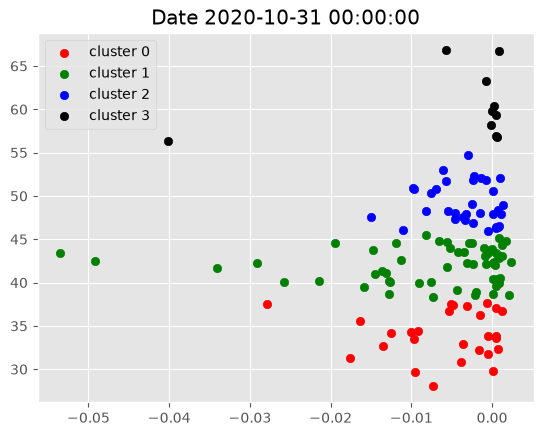

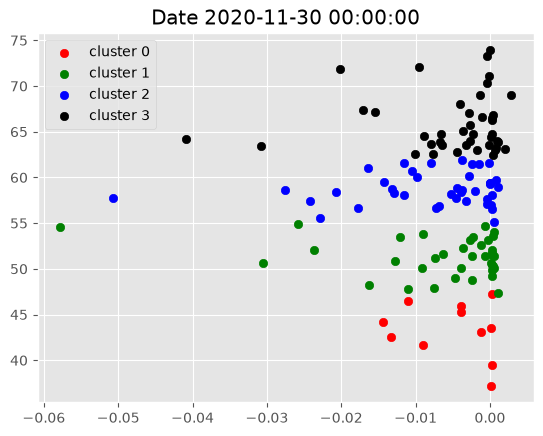

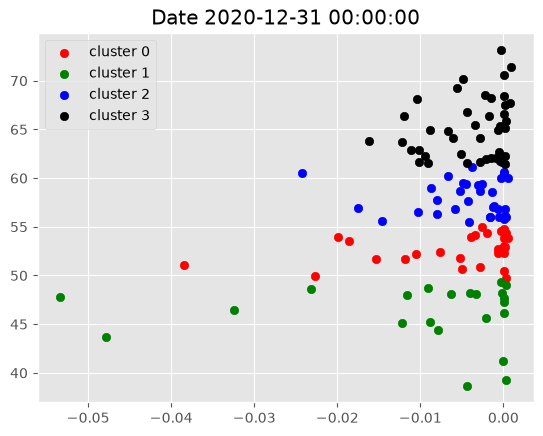

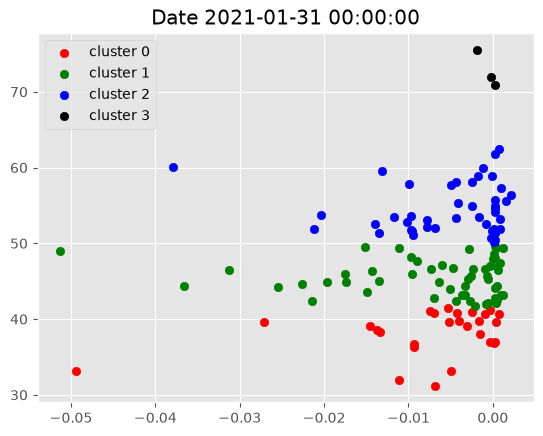

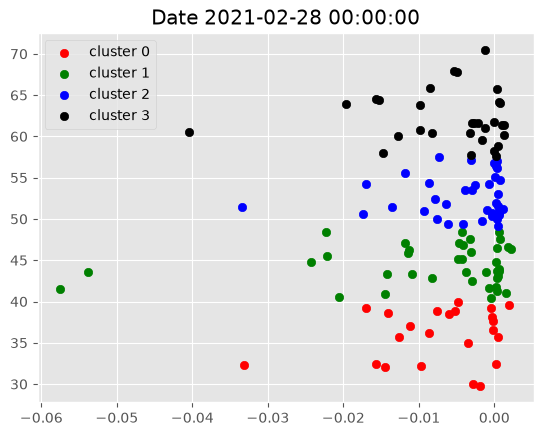

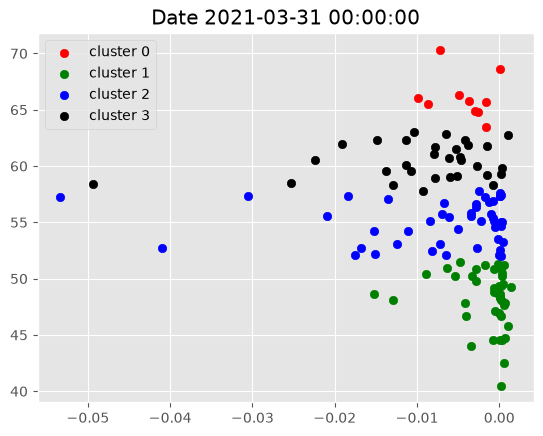

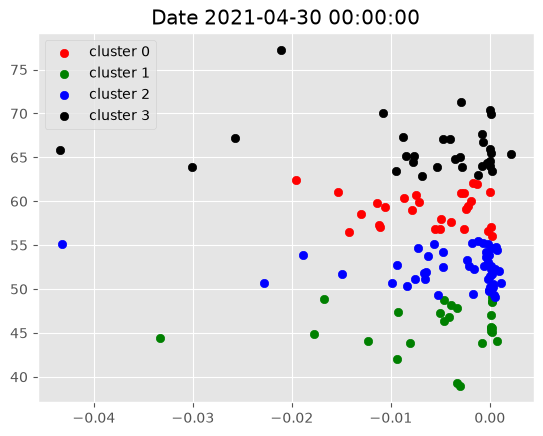

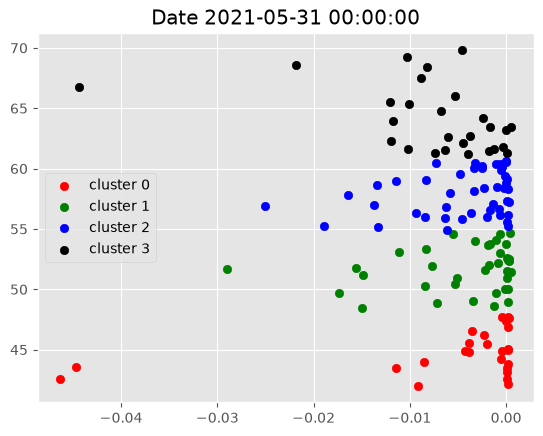

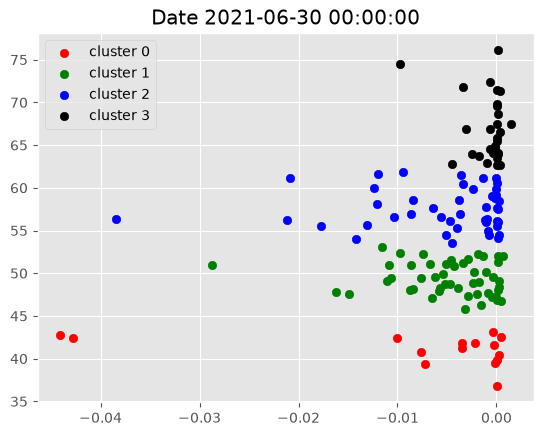

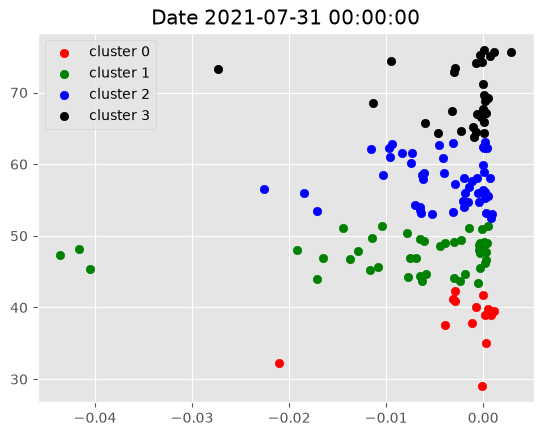

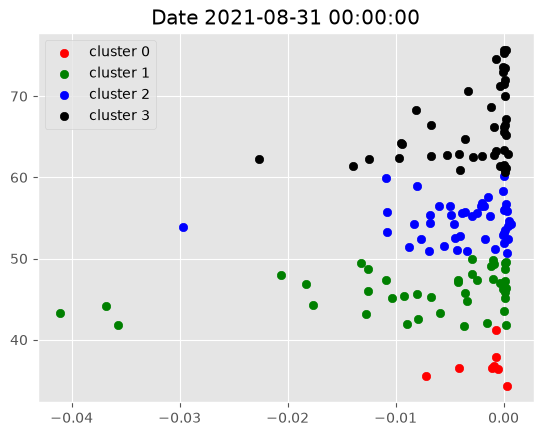

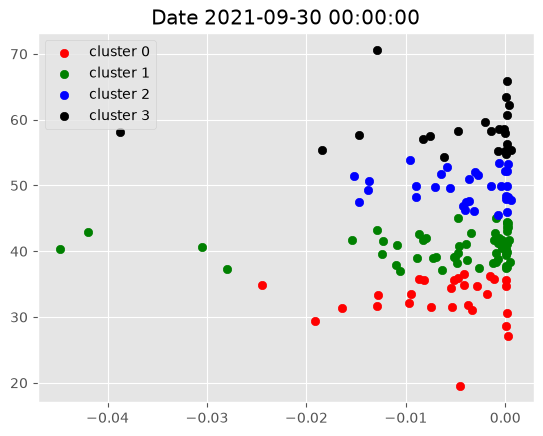

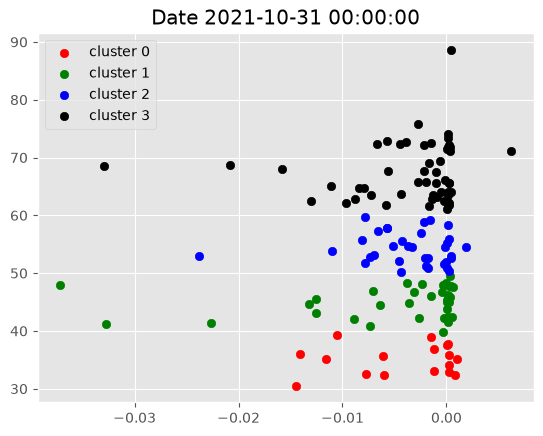

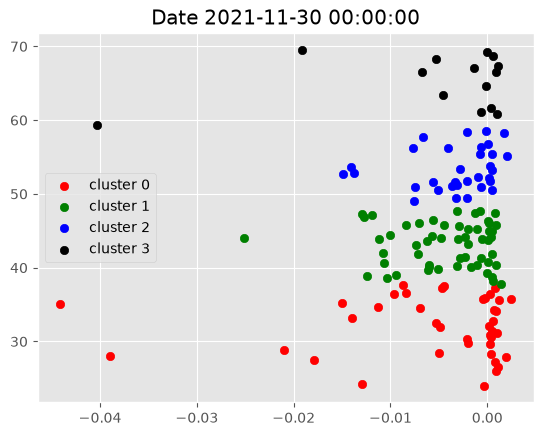

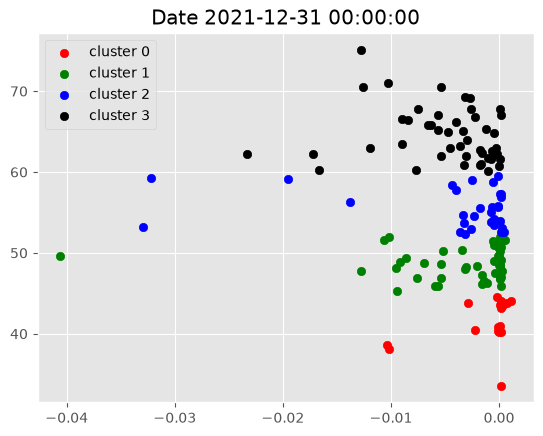

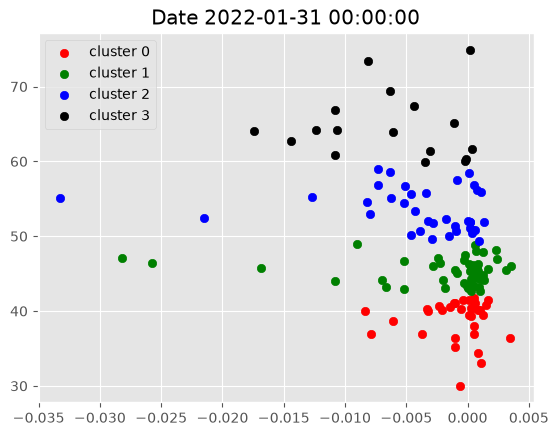

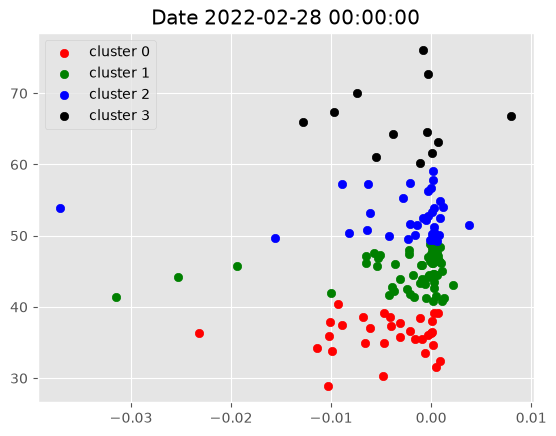

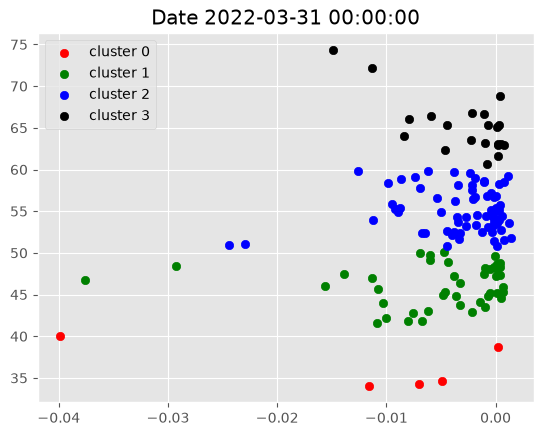

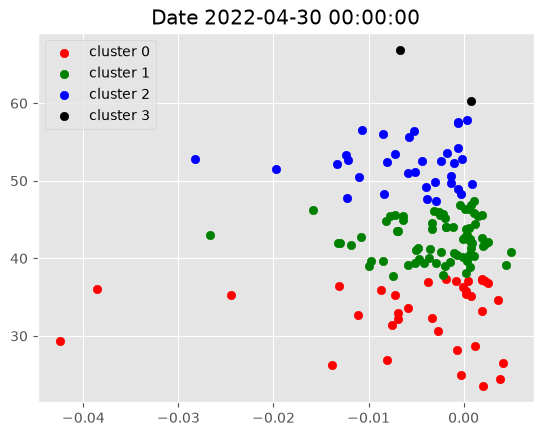

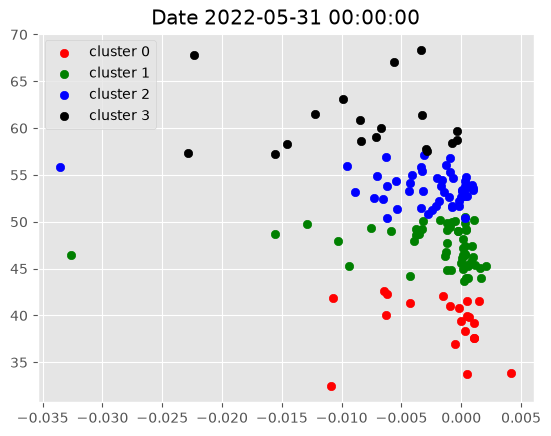

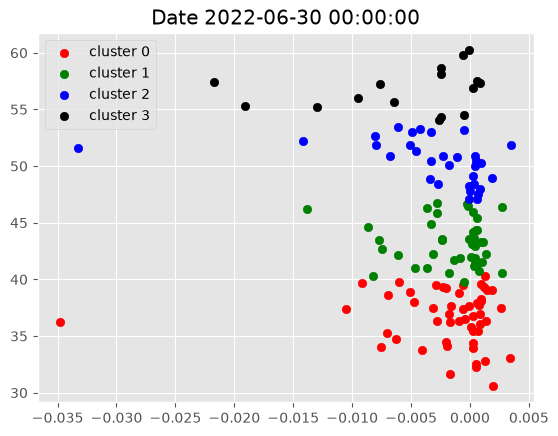

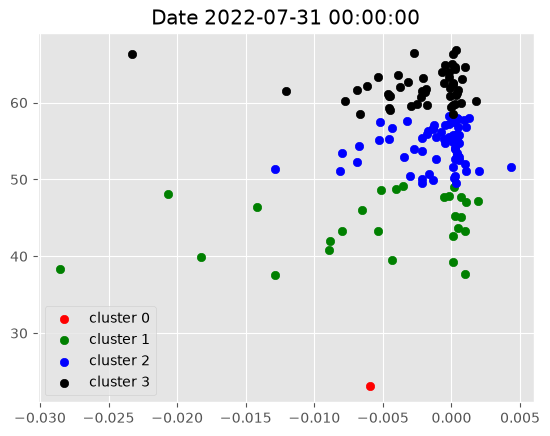

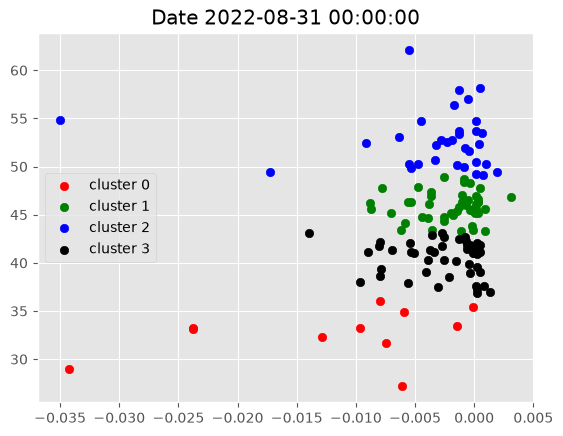

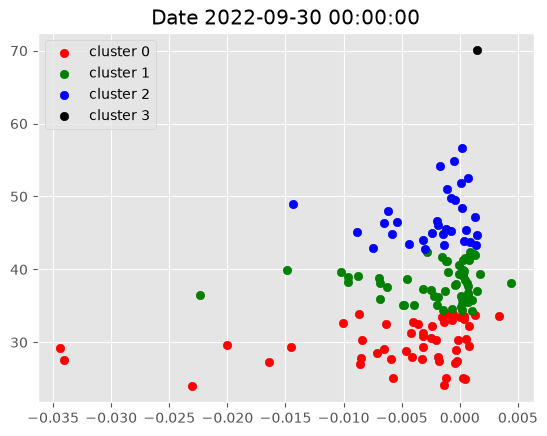

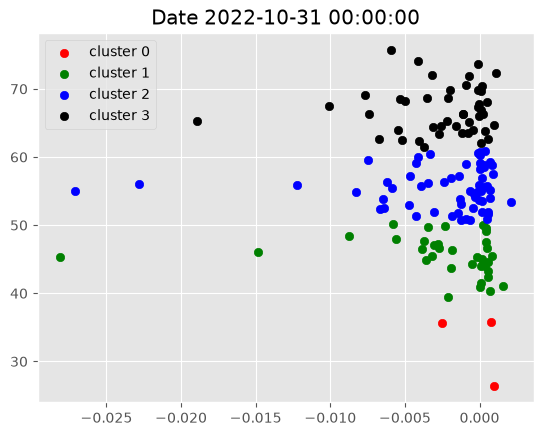

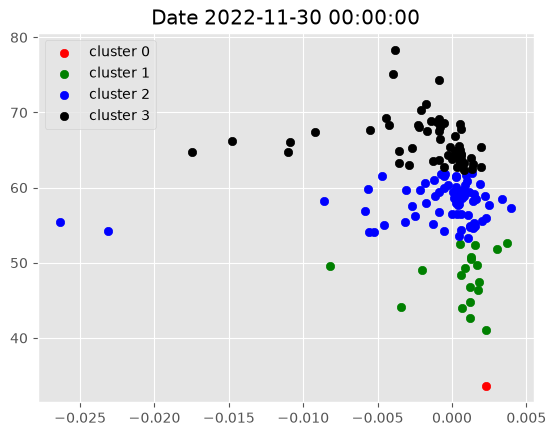

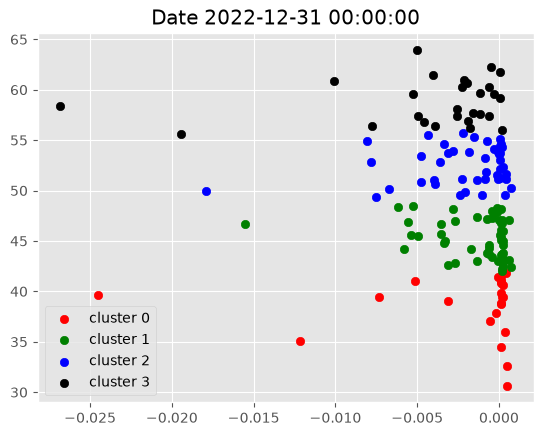

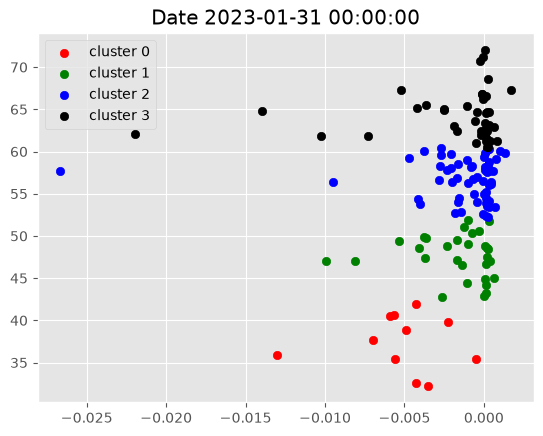

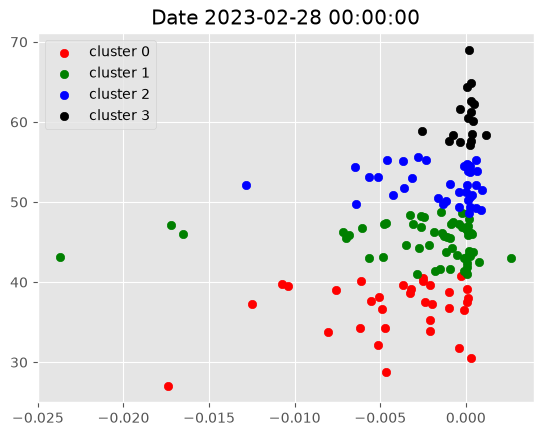

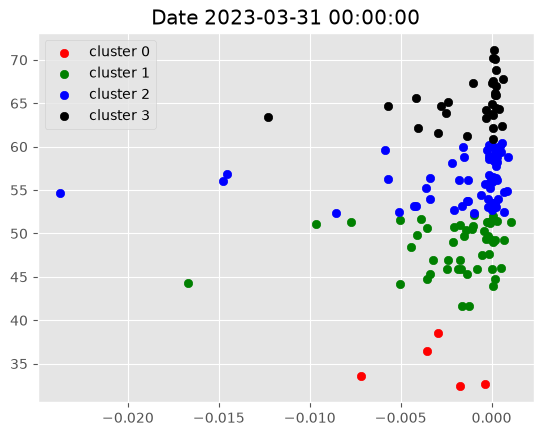

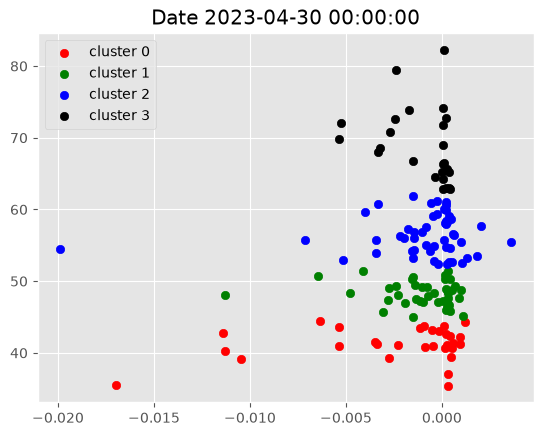

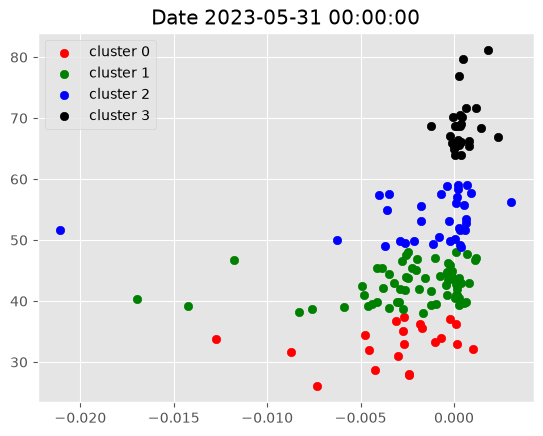

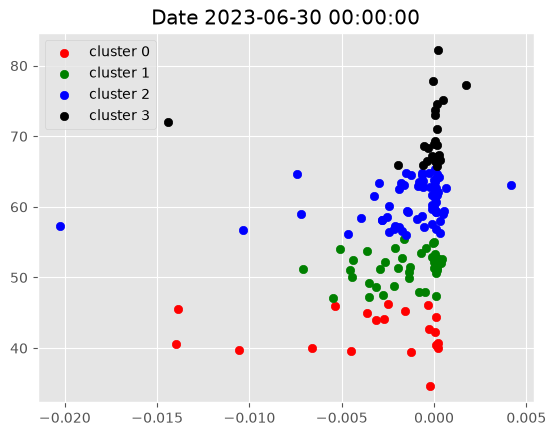

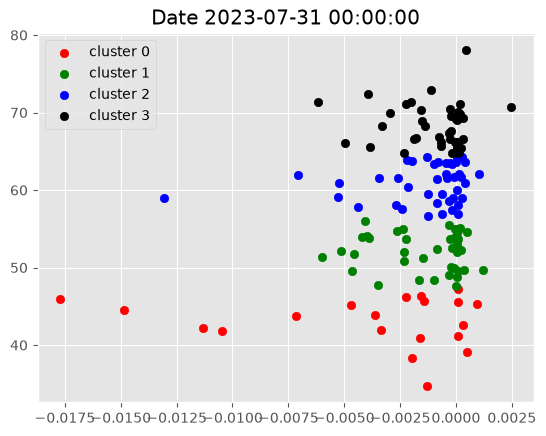

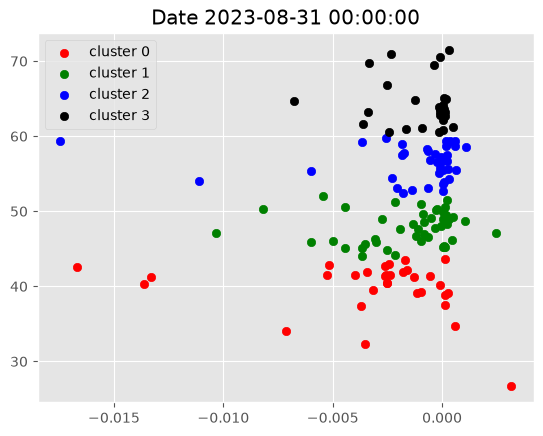

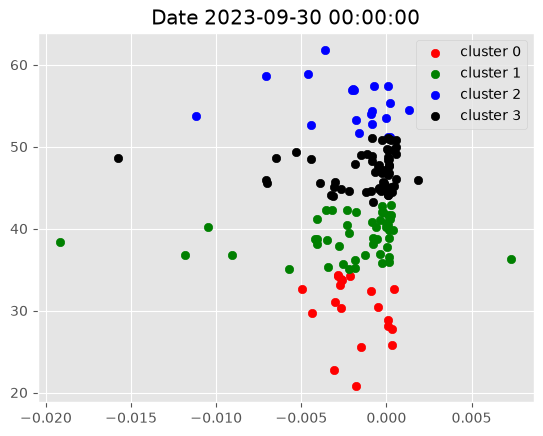

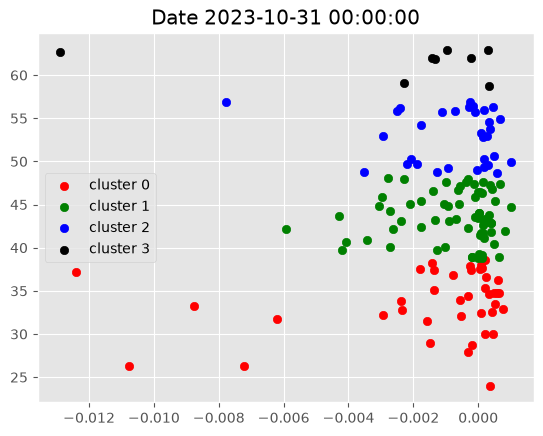

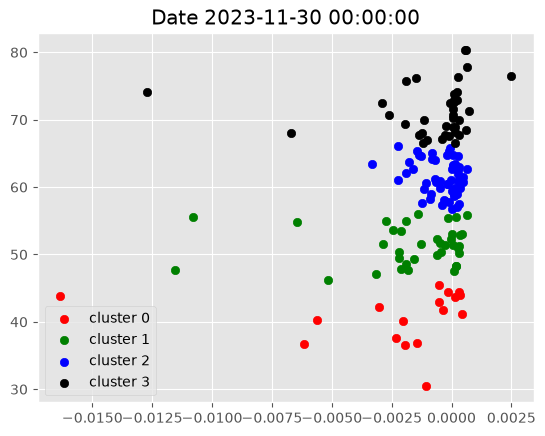

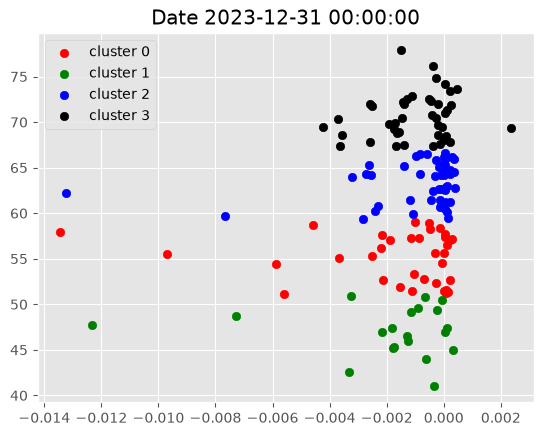

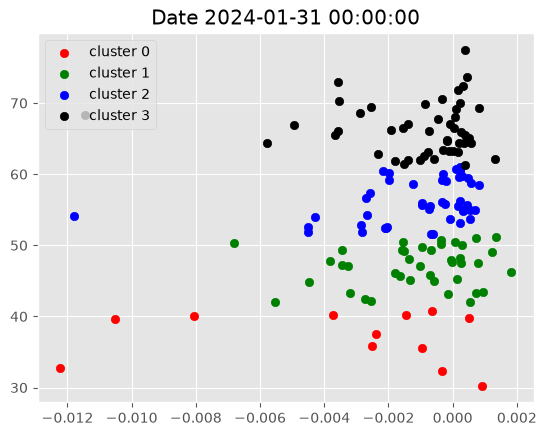

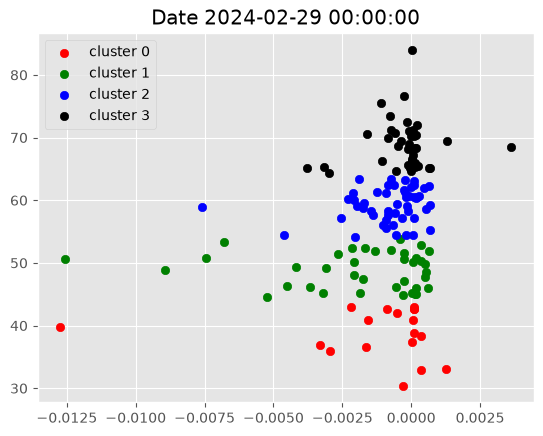

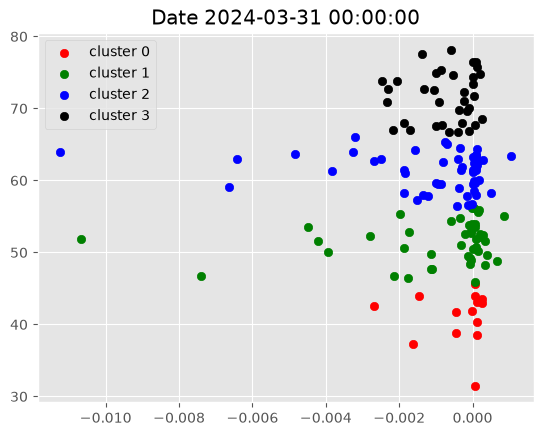

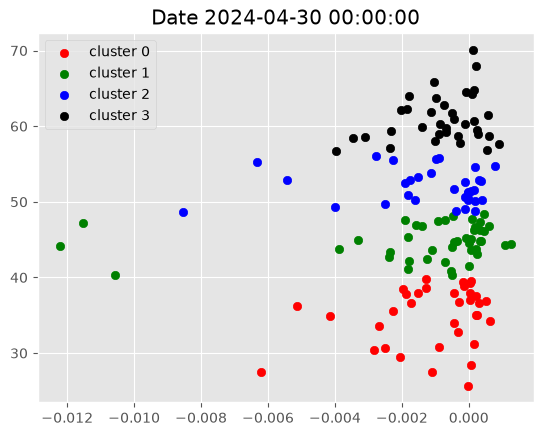

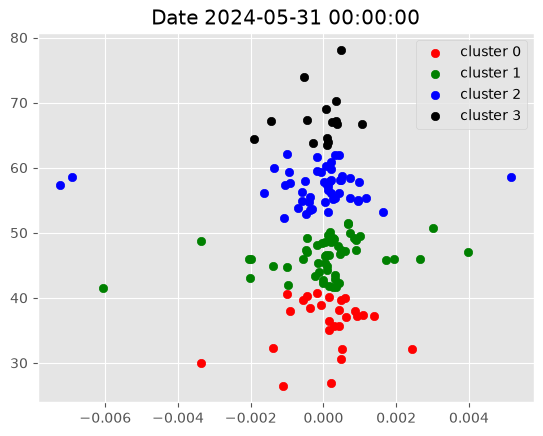

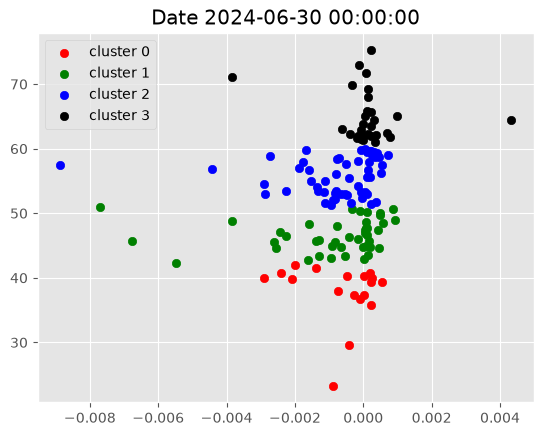

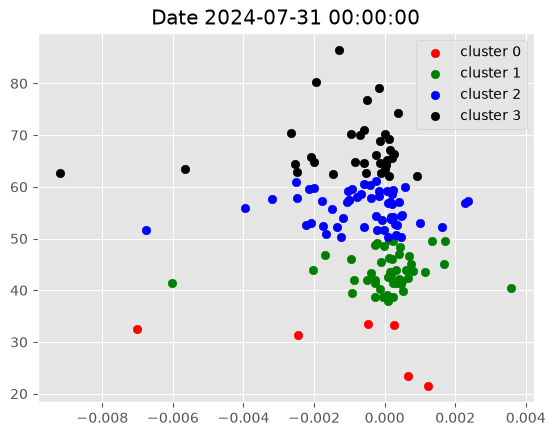

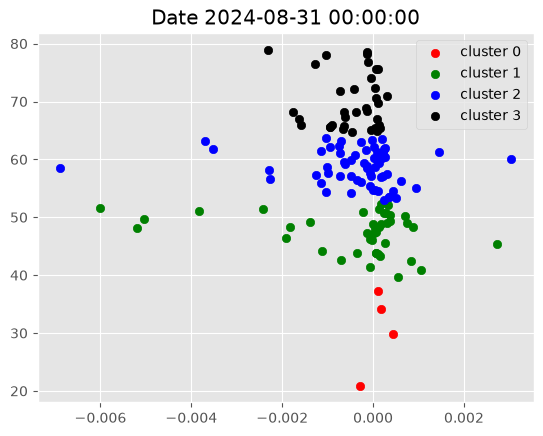

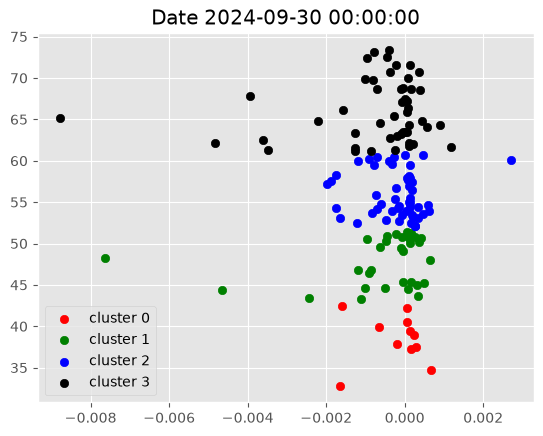

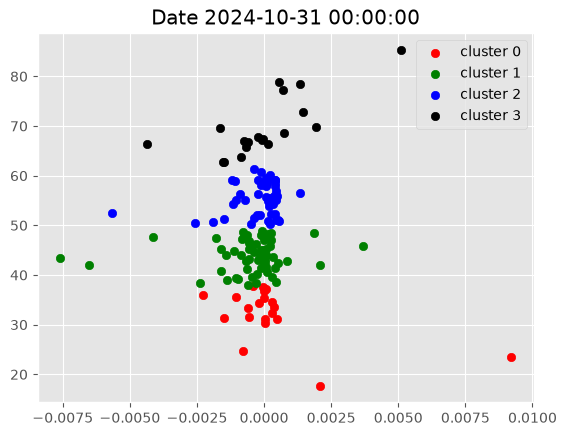

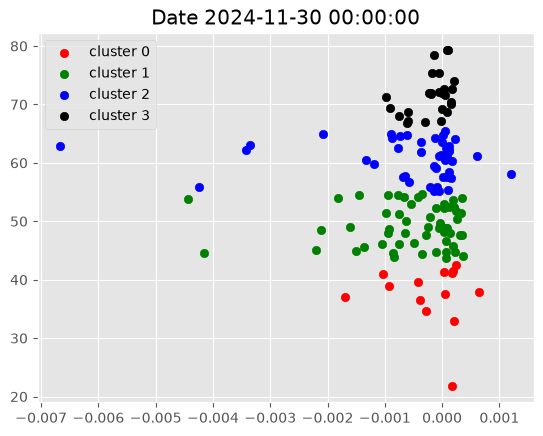

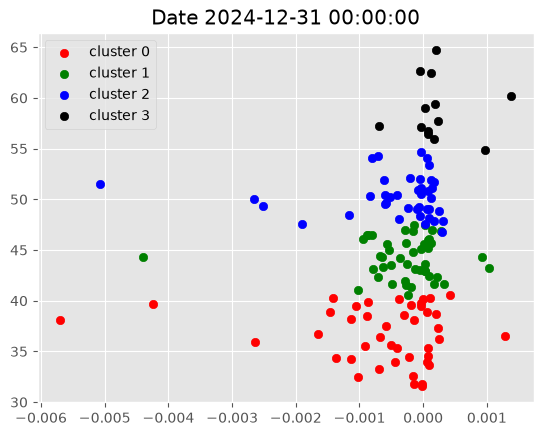

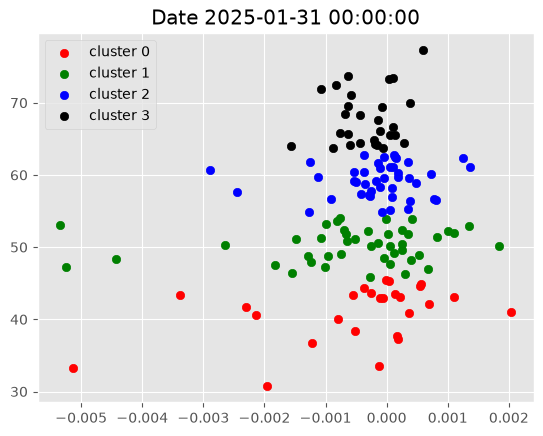

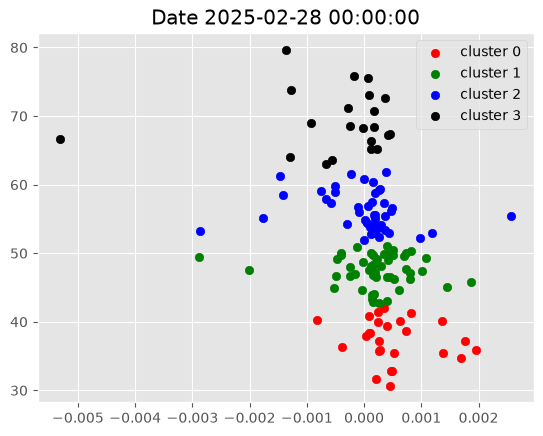

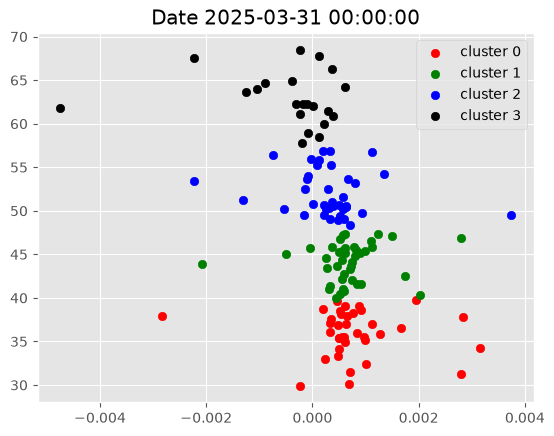

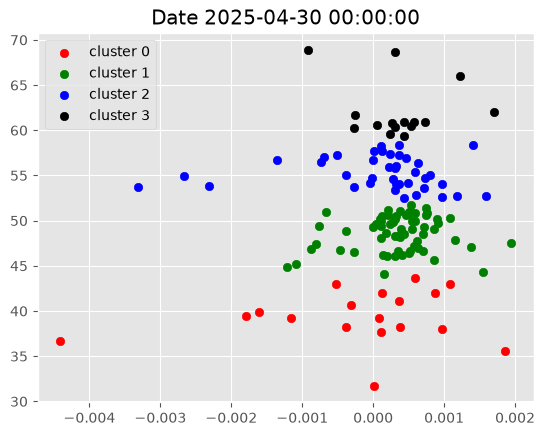

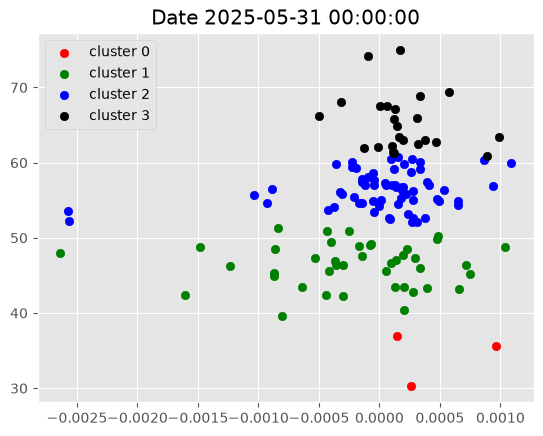

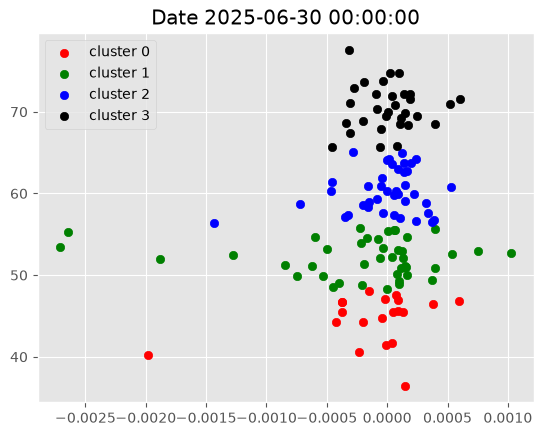

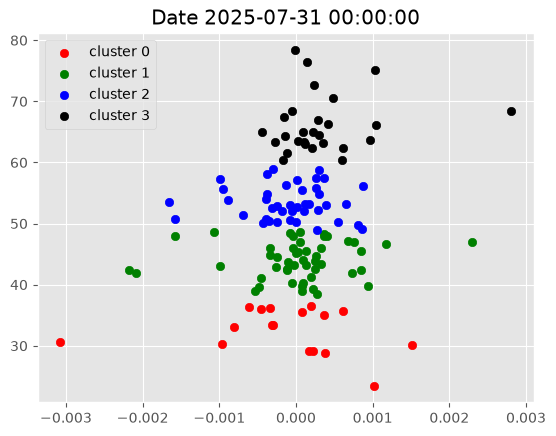

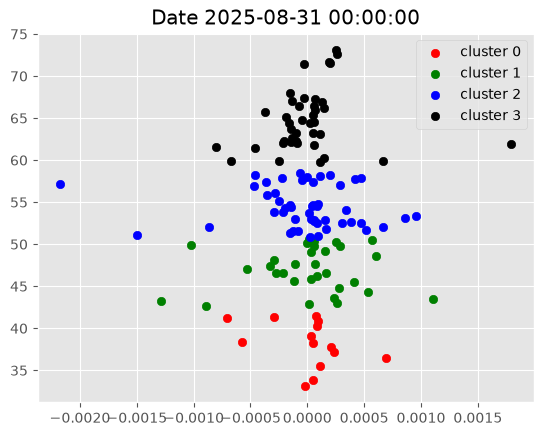

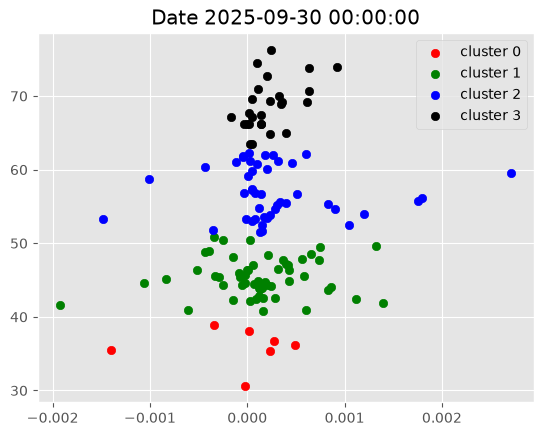

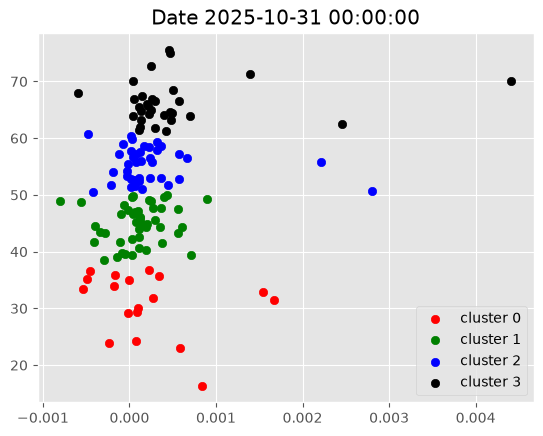

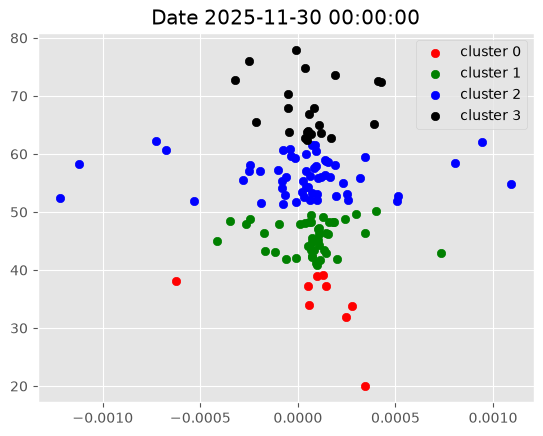

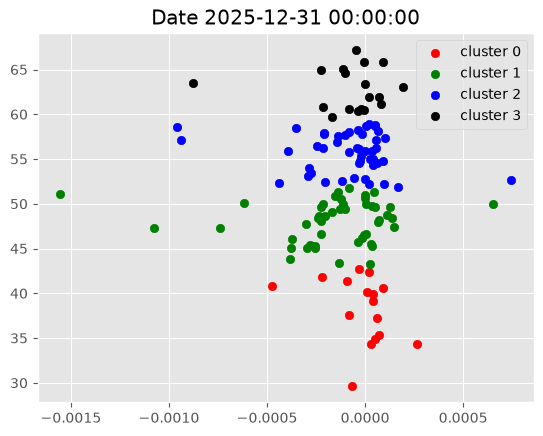

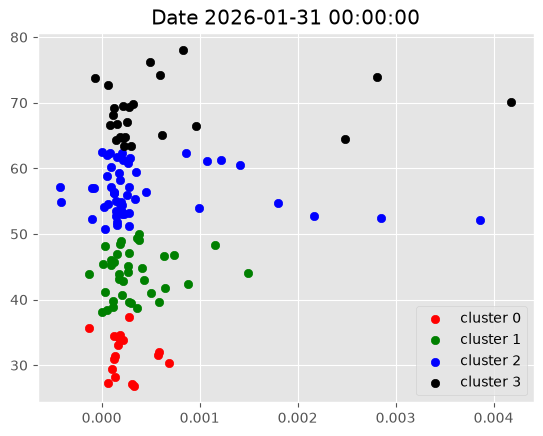

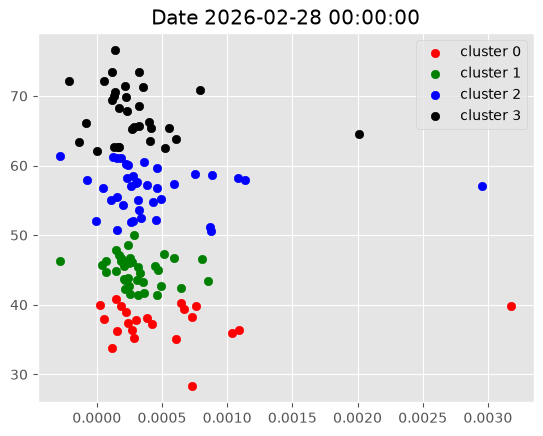

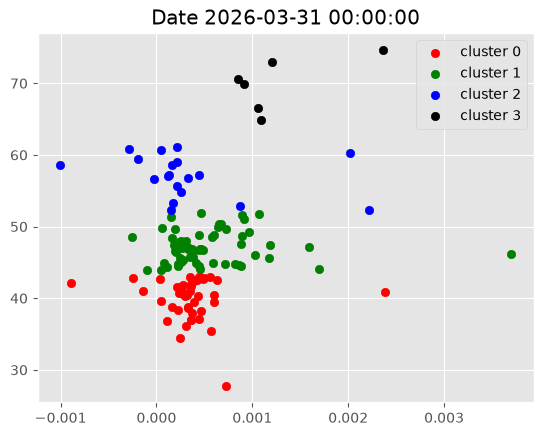

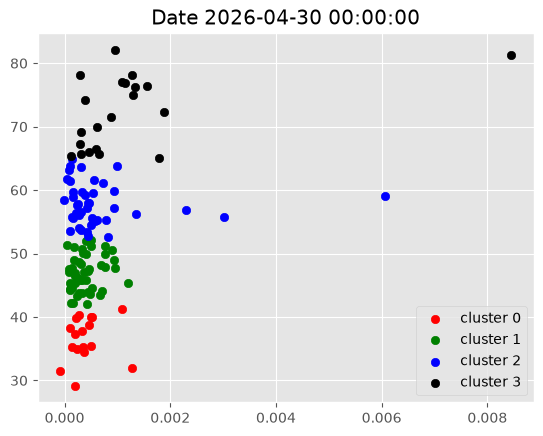

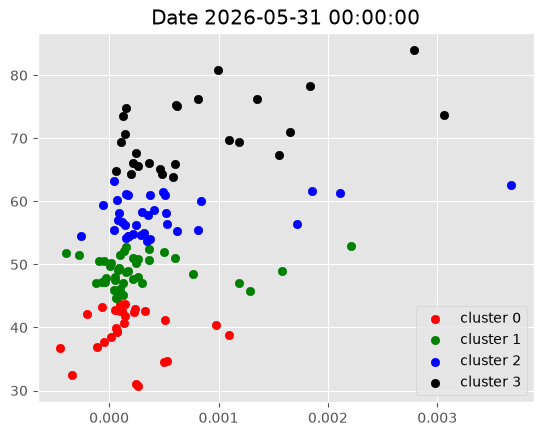

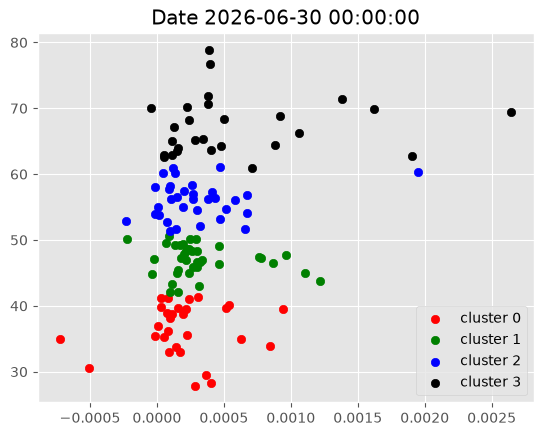

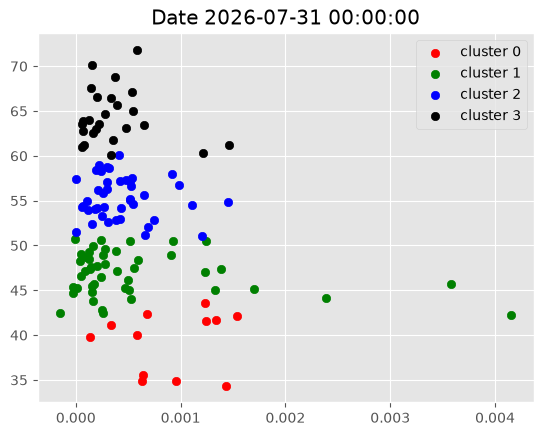

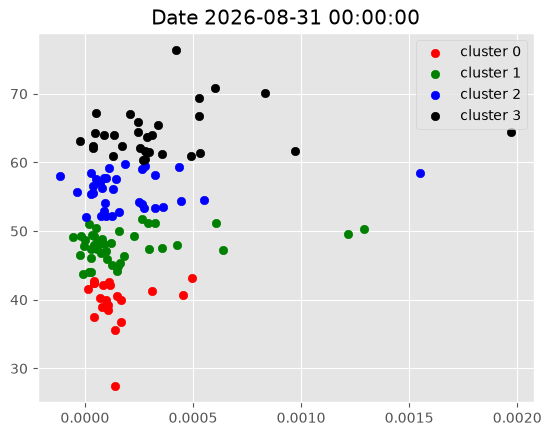

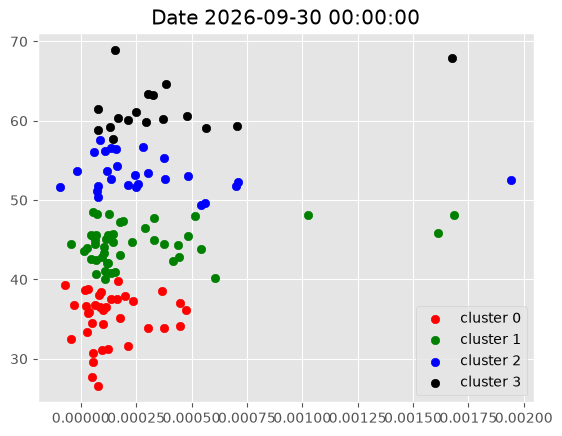

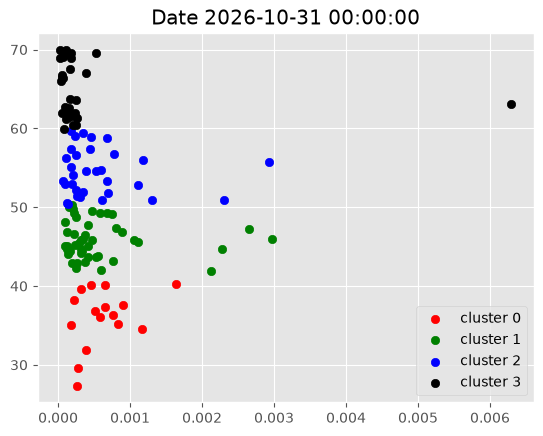

In [35]:
plt.style.use('ggplot')

for i in data.index.get_level_values('date').unique().tolist():
    g = data.xs(i, level=0)

    plt.title(f'Date {i}')
    
    plot_clusters(g)

### Apply pre-defined centroids

In [31]:
target_rsi_values = [30, 45, 55, 70]

initial_centroids = np.zeros((len(target_rsi_values), 18))

initial_centroids[:, 1] = target_rsi_values

initial_centroids

array([[ 0., 30.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.],
       [ 0., 45.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.],
       [ 0., 55.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.],
       [ 0., 70.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.]])

## 7. For each month select assets based on the cluster and form a portfolio based on the Efficient Frontier max sharpe ratio optimization
- first filter only stocks corresponding to the clsuter we choose based on our hypothesis
- momentum is persistent and my idea would be that stocks clustered around the RSI 70 centroid should continue to outperform in the following month - thus I would select stocks corresponding to cluster 3

In [94]:
# filtered_df = data[data['cluster']==3].copy()

# filtered_df = filtered_df.reset_index(level=1)

# filtered_df.index = filtered_df.index+pd.DateOffset(1)

# filtered_df = filtered_df.reset_index().set_index(['date', 'ticker'])

# dates = filtered_df.index.get_level_values('date').unique().tolist()

# fixed_dates = {}

# for d in dates:

#     fixed_dates[d.strftime('%Y-%m-%d')] = filtered_df.xs(d, level=0).index.tolist()

fixed_dates

{'2020-11-01': ['ADP',
  'ALGN',
  'DHR',
  'F',
  'GE',
  'GM',
  'GOOG',
  'GOOGL',
  'SCHW',
  'TMO'],
 '2020-12-01': ['ABBV',
  'ADP',
  'ADSK',
  'ALGN',
  'AMAT',
  'AMD',
  'AVGO',
  'BA',
  'C',
  'COST',
  'CSCO',
  'DAL',
  'DE',
  'DIS',
  'F',
  'FISV',
  'GE',
  'GM',
  'GS',
  'HON',
  'LRCX',
  'LULU',
  'MS',
  'MU',
  'NKE',
  'NXPI',
  'OXY',
  'PANW',
  'PFE',
  'QCOM',
  'RTX',
  'SBUX',
  'SCHW',
  'TGT',
  'TMUS',
  'TSLA',
  'UAL',
  'WFC',
  'WMT',
  'WYNN',
  'XYZ'],
 '2021-01-01': ['AAPL',
  'ABBV',
  'ACN',
  'ADSK',
  'ALGN',
  'AMAT',
  'AVGO',
  'BAC',
  'BKNG',
  'C',
  'CMCSA',
  'CSCO',
  'DD',
  'DE',
  'DIS',
  'EL',
  'GE',
  'GS',
  'HON',
  'ILMN',
  'ISRG',
  'JNJ',
  'JPM',
  'KO',
  'LIN',
  'LLY',
  'MA',
  'MDT',
  'MS',
  'MU',
  'ORCL',
  'PANW',
  'PEP',
  'PYPL',
  'SBUX',
  'SCHW',
  'TGT',
  'TJX',
  'TMUS',
  'TSLA',
  'V',
  'WFC'],
 '2021-02-01': ['ABT', 'ILMN', 'LLY'],
 '2021-03-01': ['AMAT',
  'AXP',
  'BAC',
  'BKNG',
  'C',
  'CAT

### Define portfolio optimization funciton 
- define a function which optimizes portfolio weights using PyPortfolioOpt package and EfficientFrontier optimizer to maximize sharpe ratio
- to optimize the weights of a given portfolio we would need to supply last 1 year prices to the function
- apply single stock weight bounds constraints for diversification (minimum half of equally weight and maximum 10% of portfolio)

In [95]:
from pypfopt.efficient_frontier import EfficientFrontier
from pypfopt import risk_models
from pypfopt import expected_returns

def optimize_weights(prices, lower_bound=0):

    returns = expected_returns.mean_historical_return(prices=prices,
                                                      frequency=252)

    cov = risk_models.sample_cov(prices=prices,
                                 frequency=252)

    ef = EfficientFrontier(expected_returns=returns,
                           cov_matrix=cov,
                          weight_bounds=(lower_bound, .1),
                          solver='SCS')

    weights = ef.max_sharpe()

    return ef.clean_weights()

- download fresh daily prices data only for short listed stocks

In [89]:
# stocks = data.index.get_level_values('ticker').unique().tolist()

# new_df = yf.download(tickers=stocks,
#                      start=data.index.get_level_values('date').unique()[0]-pd.DateOffset(months=12),
#                      end=data.index.get_level_values('date').unique()[-1],
#                      auto_adjust=False)

new_df

Price        Adj Close                                                  \
Ticker            AAPL        ABBV        ABNB         ABT         ACN   
Date                                                                     
2019-10-31   59.678551   60.223888         NaN   73.380028  165.106247   
2019-11-01   61.372288   61.889435         NaN   72.546242  167.599457   
2019-11-04   61.775322   62.828190         NaN   72.160080  167.225510   
2019-11-05   61.686569   61.957558         NaN   72.265388  166.406219   
2019-11-06   61.712936   62.139217         NaN   72.949966  168.498795   
...                ...         ...         ...         ...         ...   
2026-10-15  342.000000  283.399994  174.279999  104.680000  224.919998   
2026-10-16  343.459991  285.420013  173.699997  104.889999  229.679993   
2026-10-19  342.940002  282.679993  175.460007  104.059998  236.929993   
2026-10-20  339.500000  289.079987  176.940002  102.449997  239.119995   
2026-10-21  343.989990  284.799988  173.690002  100.510002  240.259995   

Price                                                                   ...  \
Ticker            ADBE         ADI         ADP        ADSK        ALGN  ...   
Date                                                                    ...   
2019-10-31  277.929993   94.442131  138.874969  147.360001  252.289993  ...   
2019-11-01  277.820007   96.868950  139.516968  150.250000  257.040009  ...   
2019-11-04  277.500000   98.658051  138.575333  151.270004  258.769989  ...   
2019-11-05  289.290009  100.482597  134.406448  151.729996  257.910004  ...   
2019-11-06  287.399994   99.224899  136.674942  151.509995  256.160004  ...   
...                ...         ...         ...         ...         ...  ...   
2026-10-15  251.669998  403.950012  285.649994  245.160004  149.339996  ...   
2026-10-16  245.199997  395.440002  288.899994  239.899994  147.309998  ...   
2026-10-19  247.089996  394.350006  287.029999  240.699997  149.000000  ...   
2026-10-20  256.730011  397.049988  292.750000  245.580002  150.500000  ...   
2026-10-21  255.059998  405.959991  294.500000  244.839996  151.369995  ...   

Price        Volume                                                           \
Ticker            V      VLO     VRTX        VZ     WDAY       WFC       WMT   
Date                                                                           
2019-10-31  6830800  4396600  2273400  12226600  1151900  18814700  14643900   
2019-11-01  7000200  2843000  3010600   9629100  1096200  16359300  11287800   
2019-11-04  7154800  2482500  1293300  10133300  2048900  17559900  13938000   
2019-11-05  7447500  3286200  1324200  10645400  1301600  25965300  12651300   
2019-11-06  6992500  2529800  1124000   9287600  1216200  22051100  10843200   
...             ...      ...      ...       ...      ...       ...       ...   
2026-10-15  8579000  2514900  2262500  26273200  3226700  20301900  32046300   
2026-10-16  6780000  2094300  1413000  19895900  2538500  32128500  20624500   
2026-10-19  5839500  2311900  1298700  16148200  1658000  17197700  16259400   
2026-10-20  6704500  2209000  1230000  26360300  2358200  15840800  21844200   
2026-10-21  5414500  2614900  1448600  29911500  1676200  10067800  17932000   

Price                                    
Ticker         WYNN       XOM       XYZ  
Date                                     
2019-10-31  1543700  16169100   4416100  
2019-11-01  1383800  14108700   6184900  
2019-11-04  2228900  15858200   6046700  
2019-11-05  1168000  14930400   8552000  
2019-11-06  2067300  13996500  12855600  
...             ...       ...       ...  
2026-10-15  2151100  11227700   5468600  
2026-10-16  1639500  13198300   4986100  
2026-10-19  1934200  11157900   3612200  
2026-10-20  2130000  13496400   3960200  
2026-10-21  2400500  11214000   2821500  

[1752 rows x 906 columns]

- calculate daily returns for each stock which could end up in our portfolio
- then loop over each month start, select the stocks for the month and calculate their weights for the next month
- if the maximum sharpe ratio optimization fails for a given month, apply equally weighted weights
- calcualted each day portfolio return

In [160]:
# returns_dataframe = np.log(new_df['Adj Close']).diff()

# portfolio_df = pd.DataFrame()

for start_date in fixed_dates.keys():

    try:

        end_date = (pd.to_datetime(start_date)+pd.offsets.MonthEnd(0)).strftime('%Y-%m-%d')
    
        cols = fixed_dates[start_date]
    
        optimization_start_date = (pd.to_datetime(start_date)-pd.DateOffset(months=12)).strftime('%Y-%m-%d')
    
        optimization_end_date = (pd.to_datetime(start_date)-pd.DateOffset(days=1)).strftime('%Y-%m-%d')

        optimizaton_df = new_df[optimization_start_date:optimization_end_date]['Adj Close'][cols]

        success = False
        
        try:
            weights = optimize_weights(prices=optimization_df,
                                   lower_bound=round(1/(len(optimization_df.columns)*2),3))
        
            weights = pd.DataFrame(weights, index=pd.Series(0)) 

            success = True
        except:
            print(f'Max Sharpe Optimization failed for {start_date}, continuing with Equal-Weights')

        if success==False:
            weights = pd.DataFrame([1/len(optimization_df.columns) for i in range(len(optimization_df.columns))],
                                   index=optimization_df.columns.tolist(),
                                   columns=pd.Series(0)).T
            
        temp_df = returns_dataframe['2020-11-01':'2020-11-30']
    
        temp_df = temp_df.rename_axis(columns=None).stack().to_frame('return').reset_index(level=0)\
                .merge(weights.stack().to_frame('weight').reset_index(level=0, drop=True),
                       left_index=True,
                       right_index=True)\
                .reset_index().set_index(['Date', 'index']).unstack().stack() 
    
        temp_df.index.names = ['date', 'ticker']
    
        temp_df['weighted_return'] = temp_df['return']*temp_df['weight']
    
        temp_df = temp_df.groupby(level=0)['weighted_return'].sum().to_frame('Strategy Return')
    
        portfolio_df = pd.concat([portfolio_df, temp_df], axis=0)

    except Exception as e:
        print(e)



portfolio_df    

,Strategy Return
date,
2020-11-02,0.014643
2020-11-03,0.022379
2020-11-04,0.013254
2020-11-05,0.015995
2020-11-06,0.002393
...,...
2020-11-23,0.014717
2020-11-24,0.019835
2020-11-25,-0.005070


<Axes: xlabel='date'>

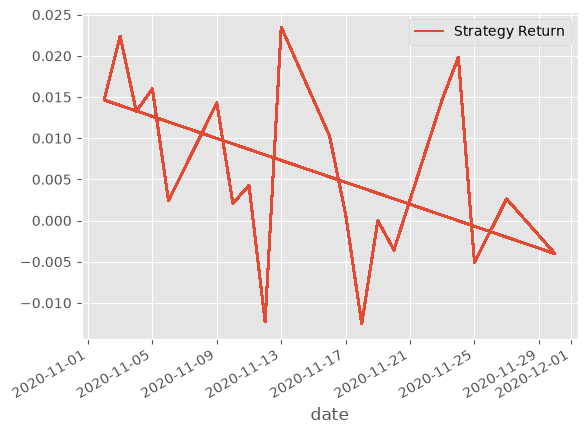

In [166]:
portfolio_df.plot()

In [132]:
temp_df

Ticker,AAPL,ABBV,ABNB,ABT,ACN,ADBE,ADI,ADP,ADSK,ALGN,...,V,VLO,VRTX,VZ,WDAY,WFC,WMT,WYNN,XOM,XYZ
Date,,,,,,,,,,,,,,,,,,,,,
2020-11-02,-0.000827,0.036347,NaN,0.022298,0.015009,-0.004843,-0.000422,0.021916,0.021837,0.073202,...,0.016538,0.032865,-0.004522,0.012381,-0.022330,0.020762,0.011822,0.046137,0.041141,0.002257
2020-11-03,0.015237,-0.003292,NaN,0.019167,0.024760,0.020202,0.010662,0.030618,0.030960,0.014230,...,0.019299,-0.010582,0.017776,0.000866,0.017846,0.008638,0.016809,-0.017019,-0.017211,0.019015
2020-11-04,0.040025,0.071718,NaN,0.017821,0.009744,0.070595,0.050399,-0.011479,-0.009794,0.038910,...,0.029454,-0.013002,0.018535,-0.009219,0.028559,-0.009552,-0.005759,0.020573,-0.005403,0.079435
2020-11-05,0.034878,-0.008608,NaN,0.017773,0.026284,0.018787,0.034801,-0.011427,0.039981,0.017327,...,0.018744,0.014268,0.020205,0.016122,0.045368,0.024939,0.010581,0.051339,-0.001807,0.022741
2020-11-06,-0.001137,-0.009006,NaN,0.007809,0.009782,-0.003713,0.023495,0.021403,0.013545,-0.028999,...,0.004190,-0.035010,0.003638,0.006513,-0.001022,-0.018988,0.015904,-0.000749,-0.011827,0.122572
2020-11-09,-0.020170,0.024154,NaN,-0.044957,0.016495,-0.048655,0.017229,0.021779,0.012260,-0.001801,...,0.069151,0.271572,0.011599,0.022135,-0.007137,0.100235,-0.015416,0.244422,0.119206,-0.073301
2020-11-10,-0.003013,0.038667,NaN,0.012898,-0.006306,-0.041473,-0.007687,0.006922,-0.060391,-0.026922,...,0.002958,-0.002399,-0.034234,0.020838,-0.043455,-0.001239,0.013975,-0.056123,0.021943,-0.067876
2020-11-11,0.029901,-0.007309,NaN,0.016469,0.016783,0.034252,0.019107,0.004666,-0.001741,-0.005485,...,-0.002864,-0.003409,0.006342,-0.001638,0.021826,0.000000,0.016489,-0.052568,-0.010363,0.064284
2020-11-12,-0.002346,-0.005620,NaN,-0.006234,-0.019131,-0.011114,-0.013927,-0.014299,-0.004386,-0.019726,...,-0.019590,-0.051727,0.007310,-0.003449,0.005428,-0.015834,0.001688,-0.056524,-0.034866,-0.027134
